# Online Retail – poking around the raw data

First pass over the raw file before I clean anything. The point here is just to find what's wrong and write it down. The actual fixing happens in the pipeline.

Data: `data/raw/online_retail.csv`, a UK online shop, Dec 2010 to Dec 2011.

In [265]:
import pandas as pd
import matplotlib.pyplot as plt


## 1. Loading it in

In [266]:
df = pd.read_csv('../data/raw/online_retail.csv')


`df` stays as the untouched raw copy.

In [267]:
shape = df.shape
print(f"Shape of the dataset: {shape[0]} rows and {shape[1]} columns")

Shape of the dataset: 541909 rows and 8 columns


541,909 rows, 8 columns.

First few rows:

In [268]:
df.head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


Each row is one product line on an invoice, not a whole order. Invoice 536365, for example, is 7 lines, all for customer 17850 at 8:26 on 1 Dec 2010.

In [269]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


Things I noticed straight away:
- InvoiceDate came in as text (`object`), not a date
- CustomerID is a float because it has blanks
- Description and CustomerID have fewer non-null values than the rest, so stuff is missing there

Making a working copy and switching the ID columns to string, so the raw one stays clean.

In [270]:
dfCopy = df.copy()

columns = ["InvoiceNo", "StockCode", "CustomerID"]
dfCopy[columns] = dfCopy[columns].astype("string")

dfCopy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  string 
 1   StockCode    541909 non-null  string 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  string 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(3), string(3)
memory usage: 33.1+ MB


From here on everything uses `dfCopy`.

## 2. Missing values

In [271]:
dfCopy.isna().sum()
# (dfCopy.isna().mean() * 100).round(2)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Only two columns have gaps. CustomerID is missing 135,080 (about a quarter of all rows!) and Description is missing 1,454.

What do the rows with no customer look like?

In [272]:
dfCopy[dfCopy["CustomerID"].isna()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,<NA>,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/2010 14:32,2.51,<NA>,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/2010 14:32,2.51,<NA>,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/2010 14:32,0.85,<NA>,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/2010 14:32,1.66,<NA>,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,12/1/2010 14:32,1.66,<NA>,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,12/1/2010 14:32,2.51,<NA>,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,12/1/2010 14:32,0.43,<NA>,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,12/1/2010 14:32,0.43,<NA>,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,12/1/2010 14:32,0.43,<NA>,United Kingdom


Mostly normal sales: real products, prices and dates. I'm guessing guest checkouts rather than broken rows. A few, like row 622, also have no description and a price of 0, and those look like a different thing.

How many rows have *anything* missing?

In [273]:
dfCopyMissingRows = dfCopy.isna().any(axis=1).sum()
print('missing rows:', dfCopyMissingRows)

missing rows: 135080


135,080, which is the exact CustomerID number.

In [274]:
dfCopy[dfCopy.isna().any(axis=1)].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,<NA>,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/2010 14:32,2.51,<NA>,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/2010 14:32,2.51,<NA>,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/2010 14:32,0.85,<NA>,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/2010 14:32,1.66,<NA>,United Kingdom


So every row missing a Description is also missing a CustomerID. The two overlap completely.

## 3. Duplicates

In [275]:
duplicate_rows = dfCopy.duplicated().sum()
print('duplicate rows:', duplicate_rows)

duplicate rows: 5268


5,268 rows match another row on every column.

Putting them side by side to make sure they really are identical:

In [276]:
dfCopy.duplicated().value_counts()          # True = duplicate row
dfCopy[dfCopy.duplicated(keep=False)].sort_values(["InvoiceNo", "StockCode","Quantity","UnitPrice", "CustomerID"])  # see them side by side


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
...,...,...,...,...,...,...,...,...
440149,C574510,22360,GLASS JAR ENGLISH CONFECTIONERY,-1,11/4/2011 13:25,2.95,15110.0,United Kingdom
461407,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,11/13/2011 11:38,0.55,17838.0,United Kingdom
461408,C575940,23309,SET OF 60 I LOVE LONDON CAKE CASES,-24,11/13/2011 11:38,0.55,17838.0,United Kingdom
529980,C580764,22667,RECIPE BOX RETROSPOT,-12,12/6/2011 10:38,2.95,14562.0,United Kingdom


Yep. 10,147 rows sit in pairs (original + copy) with the same invoice, product, qty, price and time. I can't think of a legit reason for that, so they can go.

### Are the invoices consistent?

Lines per invoice:

In [277]:
dfCopy["InvoiceNo"].value_counts().head()

InvoiceNo
573585    1114
581219     749
581492     731
580729     721
558475     705
Name: count, dtype: Int64

The biggest one (573585) has 1,114 lines. That's huge, but some customers are wholesalers so I'm leaving it.

One full invoice to see what normal looks like:

In [278]:
dfCopy[dfCopy["InvoiceNo"] == "536365"]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom


7 lines, one customer, one time, one country. Every invoice should look like this.

Does any invoice have more than one customer?

In [279]:
InvoiceNo_CustomerID_grouped = (dfCopy.groupby("InvoiceNo")["CustomerID"].nunique() > 1).sum()
print(InvoiceNo_CustomerID_grouped, "invoices have more than 1 customer")

0 invoices have more than 1 customer


No, 0. Good.

Double-checking with `transform` so I get the actual rows back:

In [280]:

# Number of rows: True = row belongs to such an invoice
dfCopy[dfCopy.groupby("InvoiceNo")["CustomerID"].transform("nunique") > 1]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


Empty, which matches.

Same check for timestamps:

In [281]:
InvoiceNo_InvoiceDate_grouped = (dfCopy.groupby("InvoiceNo")["InvoiceDate"].nunique() > 1).sum()
print(InvoiceNo_InvoiceDate_grouped, "invoices have more than 1 invoice date")

43 invoices have more than 1 invoice date


43 invoices have more than one.

In [282]:
InvoiceNo_InvoiceDate_grouped_TRANSFORM = dfCopy[dfCopy.groupby("InvoiceNo")["InvoiceDate"].transform("nunique") > 1]
InvoiceNo_InvoiceDate_grouped_TRANSFORM

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2421,536591,21427,SKULLS STORAGE BOX SMALL,1,12/1/2010 16:57,2.10,14606.0,United Kingdom
2422,536591,22135,LADLE LOVE HEART PINK,1,12/1/2010 16:57,0.42,14606.0,United Kingdom
2423,536591,90214M,"LETTER ""M"" BLING KEY RING",1,12/1/2010 16:57,1.25,14606.0,United Kingdom
2424,536591,90214V,"LETTER ""V"" BLING KEY RING",1,12/1/2010 16:57,1.25,14606.0,United Kingdom
2425,536591,90214S,"LETTER ""S"" BLING KEY RING",1,12/1/2010 16:57,1.25,14606.0,United Kingdom
...,...,...,...,...,...,...,...,...
498988,578548,23223,CHRISTMAS TREE HANGING SILVER,4,11/24/2011 15:02,0.83,17345.0,United Kingdom
498989,578548,23500,KEY RING BASEBALL BOOT ASSORTED,2,11/24/2011 15:02,1.25,17345.0,United Kingdom
498990,578548,23570,TRADITIONAL PICK UP STICKS GAME,1,11/24/2011 15:02,1.25,17345.0,United Kingdom
498991,578548,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3,11/24/2011 15:03,2.55,17345.0,United Kingdom


That's 3,347 rows. The two timestamps are always exactly 1 minute apart, so I think the clock just ticked over while the order was being entered. Nothing to fix.

## 4. Impossible values

Negative quantities first.

In [283]:
negative_quantity = dfCopy[dfCopy["Quantity"] < 0]
negative_quantity

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/2011 9:57,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,12/9/2011 10:28,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/2011 11:57,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/2011 11:58,1.25,17315.0,United Kingdom


10,624 rows, and they're two different things:
- 9,288 are cancellations (InvoiceNo starts with `C`)
- the other 1,336 look like stock write-offs: price 0, no customer, descriptions like "damaged" or "thrown away"

Prices of 0 or below:

In [284]:
dfCopy[(dfCopy["UnitPrice"] == 0) | (dfCopy["UnitPrice"] < 0)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,<NA>,United Kingdom
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,<NA>,United Kingdom
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,<NA>,United Kingdom
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,<NA>,United Kingdom
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
536981,581234,72817,NaN,27,12/8/2011 10:33,0.0,<NA>,United Kingdom
538504,581406,46000M,POLYESTER FILLER PAD 45x45cm,240,12/8/2011 13:58,0.0,<NA>,United Kingdom
538505,581406,46000S,POLYESTER FILLER PAD 40x40cm,300,12/8/2011 13:58,0.0,<NA>,United Kingdom
538554,581408,85175,NaN,20,12/8/2011 14:06,0.0,<NA>,United Kingdom


2,517 rows. 2,515 are at £0, mostly the same write-offs. The 2 negative ones are both "Adjust bad debt", so they're accounting entries, not sales.

(There's no age column in this data, so nothing to check there.)

## 5. Outliers

In [285]:
dfCopy[["Quantity", "UnitPrice"]].describe(percentiles=[.01, .25, .5, .75, .99])


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
1%,-2.000000,0.190000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
99%,100.000000,18.000000
max,80995.000000,38970.000000


98% of quantities are between -2 and 100, but the min and max are -80,995 and 80,995. Same with prices: 99% are under £18, but the max is £38,970 and the min is -£11,062. So there are definitely some extremes.

Trying the usual IQR rule:

In [286]:
def iqr_outliers(df, col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(f"{col}: normal range {lower} to {upper}")
    return df[(df[col] < lower) | (df[col] > upper)]

qty_out = iqr_outliers(dfCopy, "Quantity")
price_out = iqr_outliers(dfCopy, "UnitPrice")
len(qty_out), len(price_out)


Quantity: normal range -12.5 to 23.5
UnitPrice: normal range -3.0700000000000003 to 8.45


(58619, 39627)

- Quantity: normal range -12.5 to 23.5 → 58,619 rows (11%)
- UnitPrice: normal range -3.07 to 8.45 → 39,627 rows (7%)

Way too many to delete. Ordering 30 of something or paying £10 is completely normal for this shop, so IQR is flagging "unusual", not "wrong". I'm not using it for cleaning.

Looking at the actual extreme rows instead (I swapped the commented lines to check each one):

In [287]:
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]
# dfCopy.nlargest(5, "Quantity")[cols]
# dfCopy.nsmallest(5, "Quantity")[cols]
dfCopy.nlargest(5, "UnitPrice")[cols]
# dfCopy.nsmallest(5, "UnitPrice")[cols]


,InvoiceNo,StockCode,Description,Quantity,UnitPrice
222681,C556445,M,Manual,-1,38970.00
524602,C580605,AMAZONFEE,AMAZON FEE,-1,17836.46
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02
43703,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71
15016,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33


The top prices are all `M` (Manual, £38,970) and `AMAZONFEE`, so fees, not products. On quantity, 80,995 and 74,215 both get cancelled straight after. They're order mistakes, see Q9 in the checklist further down.

Boxplot of price:

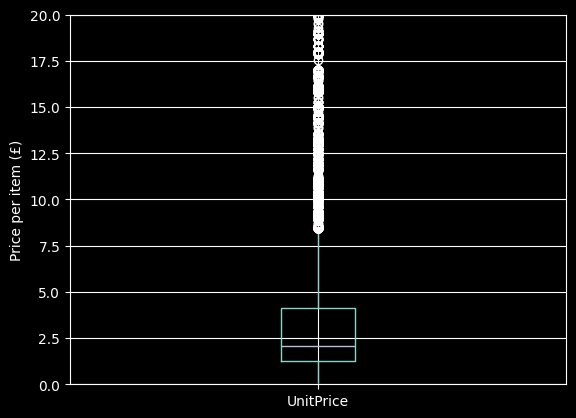

In [288]:
dfCopy.boxplot(column="UnitPrice")
plt.ylim(0, 20)
plt.ylabel("Price per item (£)")

plt.style.use('dark_background')
plt.show()

I had to zoom to £0–20, otherwise the extremes squash the box flat. Most prices sit around £1–4. The dots above ~£8.45 are the IQR outliers.

Quantity vs price:

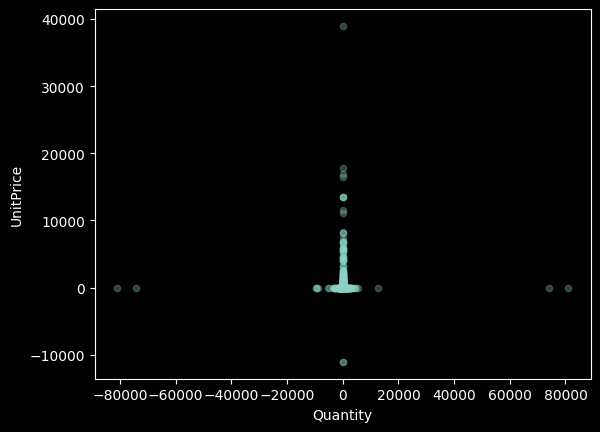

In [289]:
dfCopy.plot(kind="scatter", x="Quantity", y="UnitPrice", alpha=0.3)

plt.style.use('dark_background')
plt.show()


Two things stick out: huge quantities at low prices (the 80,995 / 74,215 mistakes) and huge prices at quantity ±1 (the fees). Everything else is crammed near zero.

## 6. Messy text

Are some descriptions the same name with different spacing or case?

In [290]:
desc = dfCopy["Description"].dropna()

print("Unique names now:", desc.nunique())
print("Unique names if spaces/case ignored:",
      desc.str.strip().str.upper().str.replace(r"\s+", " ", regex=True).nunique())


Unique names now: 4223
Unique names if spaces/case ignored: 4186


4,223 unique names, but 4,186 once I ignore spaces and case. So 37 are the same name written differently.

Product names are normally all caps, so lowercase letters are suspicious:

In [291]:
(desc[desc.str.contains("[a-z]")].value_counts()).sum()


np.int64(3036)

3,036 rows. It's a mix of typos (`TRADITIONAl`), units (`125g`, `40x40cm`) and stuff that isn't a product at all (`Manual`, `check`, `damaged`).

Same idea for StockCode:

In [292]:
sc = dfCopy["StockCode"]
sc[sc.str.contains("[a-z]")].unique()


<StringArray>
['15056bl',  '15056p',  '47566b',  '72349b',  '84872a',  '84970l',  '84970s',
  '85039a',  '18098c',  '84509c',
 ...
  '84031a',  '84031b',  '90183c',  '90184c',  '72802c',  '85049c',  '84971l',
  '85034b',  '85179a',  '47591b']
Length: 117, dtype: string

117 codes. 111 of them also exist in uppercase, e.g. `85039a` and `85039A` are the same candle. The rest are things like `m` and `gift_0001_20`.

Countries:

In [293]:
dfCopy["Country"].value_counts().sort_index()


Country
Australia                 1259
Austria                    401
Bahrain                     19
Belgium                   2069
Brazil                      32
Canada                     151
Channel Islands            758
Cyprus                     622
Czech Republic              30
Denmark                    389
EIRE                      8196
European Community          61
Finland                    695
France                    8557
Germany                   9495
Greece                     146
Hong Kong                  288
Iceland                    182
Israel                     297
Italy                      803
Japan                      358
Lebanon                     45
Lithuania                   35
Malta                      127
Netherlands               2371
Norway                    1086
Poland                     341
Portugal                  1519
RSA                         58
Saudi Arabia                10
Singapore                  229
Spain                     2533


38 countries and mostly fine. `EIRE` is Ireland and `RSA` is South Africa, they're just written as codes. `Unspecified` and `European Community` aren't really countries though.

## 7. Same product, different names

Stock codes with more than one description:

In [294]:
dfCopy.groupby("StockCode")["Description"].nunique().gt(1).sum()


np.int64(650)

650 of them.

In [295]:
dfCopy[dfCopy.groupby("StockCode")["Description"].transform('nunique').gt(1)]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom
...,...,...,...,...,...,...,...,...
541884,581585,84946,ANTIQUE SILVER T-LIGHT GLASS,12,12/9/2011 12:31,1.25,15804.0,United Kingdom
541888,581585,23145,ZINC T-LIGHT HOLDER STAR LARGE,12,12/9/2011 12:31,0.95,15804.0,United Kingdom
541889,581585,22466,FAIRY TALE COTTAGE NIGHT LIGHT,12,12/9/2011 12:31,1.95,15804.0,United Kingdom
541903,581587,23256,CHILDRENS CUTLERY SPACEBOY,4,12/9/2011 12:50,4.15,12680.0,France


113,465 rows. Some are just renames (`LUNCH BAG RED RETROSPOT` / `LUNCH BAG RED SPOTTY`). Others are warehouse notes typed into the name field (`check`, `damaged`, `?`).

And the other way round, descriptions with more than one code:

In [ ]:
(dfCopy.groupby("Description")["StockCode"].nunique() > 1).sum()

172. Mostly the lowercase-code thing again (`85034A` / `85034a`), plus notes like `?` and `CHECK` that got used on loads of codes.

So the uppercased StockCode is the reliable product ID. Description isn't.

## 8. Wrong format

CustomerID:

In [297]:
print(dfCopy["CustomerID"].dropna().head(10))
print(dfCopy["CustomerID"].dropna().str.endswith(".0").sum(), "IDs end in .0")

0    17850.0
1    17850.0
2    17850.0
3    17850.0
4    17850.0
5    17850.0
6    17850.0
7    17850.0
8    17850.0
9    13047.0
Name: CustomerID, dtype: string
406829 IDs end in .0


All 406,829 end in `.0` (`17850.0`). Pandas read the column as float because of the blanks, and converting to string kept the `.0`. It should just be `17850`. Reading it as `str` in `read_csv` avoids this, which is what `extract.py` does.

Any prices with more than 2 decimal places?

In [298]:
dfCopy[dfCopy["UnitPrice"].round(2) != dfCopy["UnitPrice"]]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
157195,550193,PADS,PADS TO MATCH ALL CUSHIONS,1,4/15/2011 9:27,0.001,13952.0,United Kingdom
279045,561226,PADS,PADS TO MATCH ALL CUSHIONS,1,7/26/2011 10:13,0.001,15618.0,United Kingdom
359871,568200,PADS,PADS TO MATCH ALL CUSHIONS,1,9/25/2011 14:58,0.001,16198.0,United Kingdom
361741,568375,BANK CHARGES,Bank Charges,1,9/26/2011 17:01,0.001,13405.0,United Kingdom


4 rows at £0.001 (`PADS` and `BANK CHARGES`). That isn't a real pounds-and-pence price.

## 9. Dates

In [299]:
dfCopy["InvoiceDate"].isna().sum()


np.int64(0)

Nothing missing, but they're still stored as text, so they need converting first.

Parsing them month-first and checking the range:

In [300]:
dates = pd.to_datetime(dfCopy["InvoiceDate"], format="%m/%d/%Y %H:%M", errors="coerce")

print("couldn't parse:", dates.isna().sum())
print("range:", dates.min(), "to", dates.max())

couldn't parse: 0
range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


All 541,909 parse fine (`12/1/2010` = 1 Dec). The range is 1 Dec 2010 08:26 to 9 Dec 2011 12:50, with no future dates.

Days of the week:

In [301]:
dates.dt.day_name().value_counts()

InvoiceDate
Thursday     103857
Tuesday      101808
Monday        95111
Wednesday     94565
Friday        82193
Sunday        64375
Name: count, dtype: int64

No Saturdays at all, so the shop was probably closed. Sunday is the quietest day.

Hours:

In [302]:
dates.dt.hour.value_counts().sort_index()

InvoiceDate
6        41
7       383
8      8909
9     34332
10    49037
11    57674
12    78709
13    72259
14    67471
15    77519
16    54516
17    28509
18     7974
19     3705
20      871
Name: count, dtype: int64

Only 6am to 8pm, mostly 10am–3pm. No midnight entries, so there are no fake default times.

Rows per month:

In [303]:
dates.dt.to_period("M").value_counts().sort_index()

InvoiceDate
2010-12    42481
2011-01    35147
2011-02    27707
2011-03    36748
2011-04    29916
2011-05    37030
2011-06    36874
2011-07    39518
2011-08    35284
2011-09    50226
2011-10    60742
2011-11    84711
2011-12    25525
Freq: M, Name: count, dtype: int64

Usually 28k–40k a month, peaking at 84,711 in Nov 2011 (Christmas). Dec 2011 only has 25,525 because the data stops on the 9th. It's a partial month, so don't compare it to the others. The only gaps are around Christmas and Easter.

## 10. Columns that disagree

Does a negative qty always mean a `C` invoice, and the other way round?

In [304]:
is_cancel = dfCopy["InvoiceNo"].str.startswith("C")

print("cancel but positive qty:", (is_cancel & (dfCopy["Quantity"] > 0)).sum())
print("negative qty but not a cancel:", (~is_cancel & (dfCopy["Quantity"] < 0)).sum())

cancel but positive qty: 0
negative qty but not a cancel: 1336


`C` invoices are always negative, none positive. But 1,336 negatives aren't cancellations. They're the write-offs from section 4 again.

There's no total column, so nothing to check qty × price against.

Any customers showing up in more than one country?

In [305]:
countries_per_customer = dfCopy.groupby("CustomerID")["Country"].nunique()
dfCopy.groupby("CustomerID")["Country"].unique()[countries_per_customer > 1]

CustomerID
12370.0           [Cyprus, Austria]
12394.0          [Belgium, Denmark]
12417.0            [Belgium, Spain]
12422.0    [Australia, Switzerland]
12429.0          [Denmark, Austria]
12431.0        [Australia, Belgium]
12455.0             [Cyprus, Spain]
12457.0       [Switzerland, Cyprus]
Name: Country, dtype: object

8 of them, e.g. 12370 shows up under both Cyprus and Austria. Could be a move, could be a typo. It's small, but it'll matter if I count customers per country.

## 11. Rows that aren't real sales

Stock codes that don't start with 5 digits. What are they?

In [306]:
odd = dfCopy[~dfCopy["StockCode"].str.match(r"^\d{5}")]

odd.groupby(odd["StockCode"].str.upper()).agg(
    rows=("StockCode", "size"),
    desc=("Description", "first"),
    price_min=("UnitPrice", "min"),
    price_max=("UnitPrice", "max"),
).sort_values("rows", ascending=False)

,rows,desc,price_min,price_max
StockCode,,,,
POST,1256,POSTAGE,0.000,8142.750
DOT,710,DOTCOM POSTAGE,0.000,4505.170
M,572,Manual,0.000,38970.000
C2,144,CARRIAGE,0.000,150.000
D,77,Discount,0.010,1867.860
S,63,SAMPLES,2.800,570.000
BANK CHARGES,37,Bank Charges,0.001,1050.150
AMAZONFEE,34,AMAZON FEE,1.000,17836.460
CRUK,16,CRUK Commission,1.600,1100.440


32 codes, 2,995 rows. Roughly:
- postage / delivery: `POST`, `DOT`, `C2`
- fees: `AMAZONFEE`, `BANK CHARGES`, `CRUK`
- manual / accounting: `M`, `D` (discount), `B` (bad debt)
- samples: `S`, `PADS` (£0.001)
- gift vouchers (`GIFT_0001_xx`) and `DCGS...` gift shop items. These are probably real, so I'm keeping them

Any test orders?

In [307]:
dfCopy[dfCopy["Description"].str.contains("test", case=False, na=False)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
332404,566064,22355,test,1,9/8/2011 15:53,0.0,<NA>,United Kingdom
338957,566573,22823,test,-22,9/13/2011 13:10,0.0,<NA>,United Kingdom
338958,566574,22823,test,22,9/13/2011 13:14,0.0,<NA>,United Kingdom


3 rows with the description "test".

## Checklist

These are the questions from the task list. Most are already covered above, so this is just the short answer for each.

**1. How many values are missing in each column?**

In [308]:
dfCopy.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

CustomerID 135,080 and Description 1,454. Nothing else is missing.

**2. How many rows are exact duplicates?**

In [309]:
dfCopy.duplicated().sum()

np.int64(5268)

5,268.

**3. How many invoice numbers start with "C"? (C = cancelled)**

In [310]:
is_cancel = dfCopy["InvoiceNo"].str.startswith("C")

print("rows:", is_cancel.sum())
print("unique invoices:", dfCopy.loc[is_cancel, "InvoiceNo"].nunique(), "of", dfCopy["InvoiceNo"].nunique())

rows: 9288
unique invoices: 3836 of 25900


9,288 rows, which is 3,836 cancelled invoices out of 25,900 (about 15%).

**4. How many rows have quantity 0 or below? How many have price 0 or below?**

In [311]:
print("quantity <= 0:", (dfCopy["Quantity"] <= 0).sum())
print("price <= 0:", (dfCopy["UnitPrice"] <= 0).sum())

quantity <= 0: 10624
price <= 0: 2517


10,624 with qty below 0 (none are exactly 0). 2,517 with price ≤ 0: 2,515 at £0 and 2 negative.

**5. Which stock codes are not products?**

In [373]:
odd = dfCopy[~dfCopy["StockCode"].str.match(r"^\d{5}")]
odd_list = odd.groupby(odd["StockCode"].str.upper()).agg(
    rows=("StockCode", "size"),                  # how many rows each code has
    descriptions=("Description", "first"),       # an example description, to see what it is
)
odd_list


,rows,descriptions
StockCode,,
AMAZONFEE,34,AMAZON FEE
B,3,Adjust bad debt
BANK CHARGES,37,Bank Charges
C2,144,CARRIAGE
CRUK,16,CRUK Commission
D,77,Discount
DCGS0003,5,BOXED GLASS ASHTRAY
DCGS0004,1,HAYNES CAMPER SHOULDER BAG
DCGS0055,1,None


32 odd codes, each with a row count and an example description so I can tell what it is.

The DCGS ones are real gift shop items, so taking those out:

In [376]:
odd_list = odd_list[~odd_list.index.str.startswith("DCGS")]
print(odd_list.index.tolist())


['AMAZONFEE', 'B', 'BANK CHARGES', 'C2', 'CRUK', 'D', 'DOT', 'GIFT_0001_10', 'GIFT_0001_20', 'GIFT_0001_30', 'GIFT_0001_40', 'GIFT_0001_50', 'M', 'PADS', 'POST', 'S']


What's left: POST, DOT, C2 (postage), M (manual), D (discount), S (samples), BANK CHARGES, AMAZONFEE, CRUK, B (bad debt) and PADS. This is the list that went into `NON_PRODUCT_CODES` in config.

The gift vouchers (GIFT_0001_xx) also have an odd format, but they're real. See section 11.

**6. Which country names look wrong or unclear?**

In [378]:
dfCopy["Country"].value_counts().sort_index()

Country
Australia                 1259
Austria                    401
Bahrain                     19
Belgium                   2069
Brazil                      32
Canada                     151
Channel Islands            758
Cyprus                     622
Czech Republic              30
Denmark                    389
EIRE                      8196
European Community          61
Finland                    695
France                    8557
Germany                   9495
Greece                     146
Hong Kong                  288
Iceland                    182
Israel                     297
Italy                      803
Japan                      358
Lebanon                     45
Lithuania                   35
Malta                      127
Netherlands               2371
Norway                    1086
Poland                     341
Portugal                  1519
RSA                         58
Saudi Arabia                10
Singapore                  229
Spain                     2533


`Unspecified` (446 rows) and `European Community` (61) aren't countries. `EIRE` and `RSA` are fine, they're just codes.

**7. How many descriptions have spaces at the start or end?**

In [314]:
desc = dfCopy["Description"].dropna()
(desc != desc.str.strip()).sum()

np.int64(113452)

113,452. I had to `dropna()` first. Without it the 1,454 blanks get counted too and you get 114,906.

**8. How many stock codes have more than one description?**

In [315]:
(dfCopy.groupby("StockCode")["Description"].nunique() > 1).sum()

np.int64(650)

650, same as section 7.

**9. What is the biggest quantity, and does anything look strange about it?**

In [316]:
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "CustomerID"]
dfCopy.sort_values("Quantity")[cols].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,12/9/2011 9:27,16446.0
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1/18/2011 10:17,12346.0
225529,556690,23005,printing smudges/thrown away,-9600,6/14/2011 10:37,<NA>
225530,556691,23005,printing smudges/thrown away,-9600,6/14/2011 10:37,<NA>
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,12/2/2010 14:23,15838.0


This is sorted ascending, so these are the *smallest*: -80,995 and -74,215, both on `C` invoices.

Now the other end:

In [317]:
dfCopy.sort_values("Quantity")[cols].tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,CustomerID
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,10/27/2011 12:26,12901.0
74614,542504,37413,NaN,5568,1/28/2011 12:03,<NA>
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,11/25/2011 15:57,13256.0
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1/18/2011 10:01,12346.0
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,12/9/2011 9:15,16446.0


The biggest is 80,995 of "PAPER CRAFT, LITTLE BIRDIE" (customer 16446, 9:15 on 9 Dec 2011). The -80,995 is the same product and customer, cancelled 12 minutes later. 74,215 / -74,215 (customer 12346) is the same story. Pretty clearly typos that got cancelled, not real orders.

## Summary

| Check | What I found |
|---|---|
| Missing values | 135,080 rows with no CustomerID, 1,454 with no Description (always the same rows) |
| Duplicates | 5,268 exact copies |
| Impossible values | negative qty (cancellations + write-offs), £0 prices, 2 negative "bad debt" prices |
| Outliers | 2 huge mistaken orders (both cancelled). The big prices are all fees |
| Messy text | extra spaces, mixed case, lowercase stock codes |
| Same thing, different names | 650 codes with more than one description |
| Wrong format | CustomerID as `17850.0`, InvoiceDate stored as text |
| Dates | all fine. Dec 2011 is only a partial month |
| Columns disagree | 1,336 negative qty that aren't cancellations, 8 customers in 2 countries |
| Not real sales | ~3,000 fee / postage / adjustment rows |

## Next

The codes and limits I settled on here (non-product codes, country fixes, date format, max quantity) are in `pipeline/config.py`, so the cleaning step can use them.